### Task 1: Designing a Heuristic for a Warehouse Robot

In [1]:
import math
import networkx as nx
import matplotlib.pyplot as plt


# 1. Coordinates of warehouse locations

locations = {
    "Receiving_Area": (0, 0),
    "Storage_A": (2, 1),
    "Storage_B": (1, 4),
    "Sorting_Area": (4, 2),
    "Inspection_Area": (5, 5),
    "Packing_Station": (7, 6)
}


# 2. Weighted warehouse graph

warehouse_graph = {
    "Receiving_Area": {
        "Storage_A": 2.2,
        "Storage_B": 4.1
    },

    "Storage_A": {
        "Sorting_Area": 2.2
    },

    "Storage_B": {
        "Inspection_Area": 5.0,
        "Sorting_Area": 6.0
    },

    "Sorting_Area": {
        "Inspection_Area": 3.2,
        "Packing_Station": 5.0
    },

    "Inspection_Area": {
        "Packing_Station": 2.2
    }
}


# 3. Euclidean heuristic


def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)



# 4. Calculate heuristic values

goal = "Packing_Station"

print("Heuristic Values")
print("----------------")

for location in locations:
    h = heuristic(location, goal)
    print(f"{location:20s} {h:.2f}")

Heuristic Values
----------------
Receiving_Area       9.22
Storage_A            7.07
Storage_B            6.32
Sorting_Area         5.00
Inspection_Area      2.24
Packing_Station      0.00


#### NetworkX visualization: Since Task 1 does not ask GBFS/A* to find a path, you are supposed highlight the actual minimum-cost path merely for visualization:

In [2]:
# 5. Create NetworkX graph

G = nx.DiGraph()

for node, neighbors in warehouse_graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

# 6. Find minimum-cost path
## The primary function to find the shortest path in the Python networkx library 
### 1. Unweighted shortest path (ignores 'weight', finds fewest number of edges)
### 2. Weighted shortest path (minimizes the sum of the 'weight' attribute)
solution_path = nx.shortest_path( # reaturn the path e.g. A → B → C
    G,#pass the graph object
    source="Receiving_Area",
    target="Packing_Station",
    weight="weight"
)

solution_cost = nx.shortest_path_length( #return the numeric value
    G,
    source="Receiving_Area",
    target="Packing_Station",
    weight="weight"
)

print("\nMinimum cost path:")
print(" -> ".join(solution_path))
print(f"Total cost: {solution_cost:.2f}")


Minimum cost path:
Receiving_Area -> Storage_A -> Sorting_Area -> Packing_Station
Total cost: 9.40


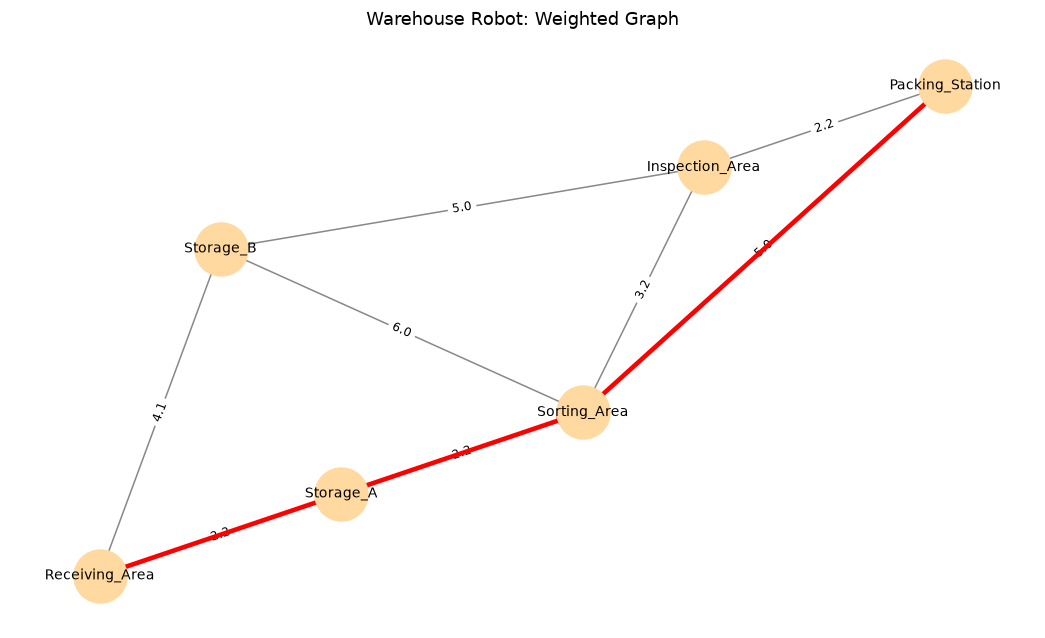

In [3]:
# 7. Visualize graph

pos = locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(G, pos, node_color="#ffd9a0", node_size=1200)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edges(G, pos, arrows=True, edge_color="#888888")
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "weight"), font_size=8)

path_edges = list(zip(solution_path, solution_path[1:]))
nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3)


plt.title("Warehouse Robot: Weighted Graph")
plt.axis("off")
plt.show()

In [4]:
# 8. Verify heuristic condition

print("\nHeuristic Condition Verification")
print("***********************************")

for node in warehouse_graph:

    for neighbor, cost in warehouse_graph[node].items():

        h1 = heuristic(node, goal)
        h2 = heuristic(neighbor, goal)
        ok = h1 <= cost + h2
        print(
            f"h({node})={h1:5.2f} <= {cost:4.1f} + "
            f"h({neighbor})={h2:5.2f}  ->  {ok}"
        )


Heuristic Condition Verification
***********************************
h(Receiving_Area)= 9.22 <=  2.2 + h(Storage_A)= 7.07  ->  True
h(Receiving_Area)= 9.22 <=  4.1 + h(Storage_B)= 6.32  ->  True
h(Storage_A)= 7.07 <=  2.2 + h(Sorting_Area)= 5.00  ->  True
h(Storage_B)= 6.32 <=  5.0 + h(Inspection_Area)= 2.24  ->  True
h(Storage_B)= 6.32 <=  6.0 + h(Sorting_Area)= 5.00  ->  True
h(Sorting_Area)= 5.00 <=  3.2 + h(Inspection_Area)= 2.24  ->  True
h(Sorting_Area)= 5.00 <=  5.0 + h(Packing_Station)= 0.00  ->  True
h(Inspection_Area)= 2.24 <=  2.2 + h(Packing_Station)= 0.00  ->  False


**Observation:** Euclidean distance never overestimates the real remaining cost, so the condition `h(n) <= cost(n,m) + h(m)` holds for 7 of the 8 edges; the only exception is `Inspection_Area -> Packing_Station`, where the given cost (2.2) is marginally lower than the straight-line distance (2.24).

### Task 2: Greedy Best-First Search for Airport Baggage Handling

In [5]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# 1. Airport coordinates

locations = {
    "Baggage_Area": (0, 0),
    "Security": (2, 1),
    "Checkpoint": (1, 4),
    "Food_Court": (4, 2),
    "Terminal_Hall": (5, 5),
    "Departure_Gate": (8, 6)
}

# 2. Weighted graph


airport_graph = {
    "Baggage_Area": {
        "Security": 2.2,
        "Checkpoint": 4.1
    },

    "Security": {
        "Food_Court": 2.2
    },

    "Checkpoint": {
        "Terminal_Hall": 5.0
    },

    "Food_Court": {
        "Terminal_Hall": 3.2,
        "Departure_Gate": 6.0
    },

    "Terminal_Hall": {
        "Departure_Gate": 3.2
    },

    "Departure_Gate": {}
}

# 3. Euclidean heuristic


def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)


# 4. GBFS


def greedy_best_first_search(start, goal, graph):

    frontier = [(heuristic(start, goal), start)]
    came_from = {start: None}
    expanded = []
    visited = set()

    while frontier:
        _, current = heapq.heappop(frontier)

        if current in visited:
            continue

        visited.add(current)
        expanded.append(current)

        if current == goal:
            break

        for neighbor in graph[current]:
            if neighbor not in visited and neighbor not in came_from:
                came_from[neighbor] = current
                heapq.heappush(
                    frontier,
                    (heuristic(neighbor, goal), neighbor)
                )

    # Reconstruct path
    if goal not in came_from:
        return expanded, None, 0.0

    path = []
    node = goal

    while node is not None:
        path.append(node)
        node = came_from[node]

    path.reverse()

    # Calculate actual path cost
    total_cost = 0.0

    for a, b in zip(path, path[1:]):
        total_cost += graph[a][b]

    return expanded, path, total_cost


# 5. Run GBFS


start = "Baggage_Area"
goal = "Departure_Gate"

expansion_order, path, total_cost = greedy_best_first_search(
    start, goal, airport_graph
)

print("GBFS")
print("--------------------------------")
print("Expansion order:")
print(" -> ".join(expansion_order))

print("\nSolution path:")
print(" -> ".join(path))

print(f"\nTotal path cost: {total_cost:.2f}")

GBFS
--------------------------------
Expansion order:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Solution path:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Total path cost: 12.30


#### NetworkX visualization

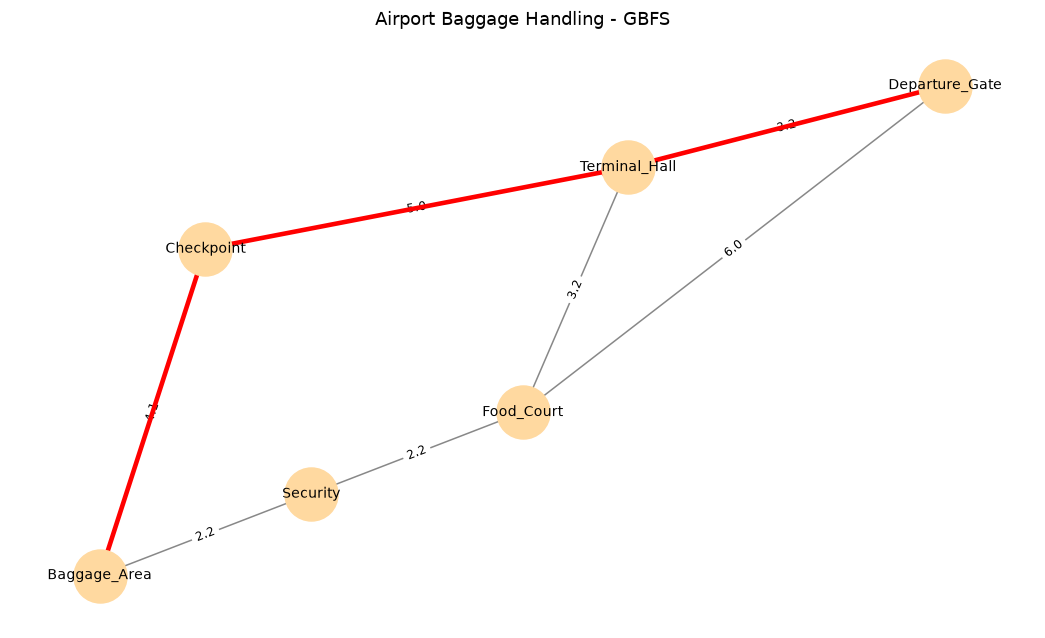

In [6]:
# 6. NetworkX visualization

G = nx.DiGraph()

for node, neighbors in airport_graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(G, pos, node_color="#ffd9a0", node_size=1200)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edges(G, pos, arrows=True, edge_color="#888888")
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "weight"), font_size=8)

path_edges = list(zip(path, path[1:]))
nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3)

plt.title("Airport Baggage Handling - GBFS")
plt.axis("off")
plt.show()

**Observation - how the heuristic guided GBFS:** GBFS ranks neighbours only by `h(n)` (straight-line distance to Departure_Gate): Checkpoint 7.28 < Security 7.81, so the search goes Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate and never expands Security / Food_Court. That path costs **12.30**, while the route through Security -> Food_Court -> Departure_Gate costs only **10.40** - GBFS ignores `g(n)`, so it is fast (4 nodes expanded) but not optimal.

### Task 3: A* Search for Emergency Supply Robot

In [7]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt


# 1. Hospital coordinates


locations = {
    "Pharmacy": (0, 0),
    "Main_Corridor": (2, 1),
    "Patient_Wing": (1, 4),
    "Nursing_Station": (4, 2),
    "Laboratory": (5, 5),
    "Emergency_Ward": (8, 6)
}


# 2. Hospital weighted graph


hospital_graph = {
    "Pharmacy": {
        "Main_Corridor": 2.2,
        "Patient_Wing": 4.1
    },

    "Main_Corridor": {
        "Nursing_Station": 2.2
    },

    "Patient_Wing": {
        "Laboratory": 5.0
    },

    "Nursing_Station": {
        "Laboratory": 3.2,
        "Emergency_Ward": 6.0
    },

    "Laboratory": {
        "Emergency_Ward": 3.2
    },

    "Emergency_Ward": {}
}

# 3. Euclidean heuristic


def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

# 4. Path reconstruction

def reconstruct_path(came_from, current):

    path = []
    while current is not None:
        path.append(current)
        current = came_from[current]
    path.reverse()
    return path

# 5. A* Search
def a_star_search(start, goal, graph):
    frontier = [(heuristic(start, goal), start)]
    g_cost = {start: 0.0}
    came_from = {start: None}
    expanded = []
    visited = set()

    while frontier:
        _, current = heapq.heappop(frontier)

        if current in visited:
            continue

        visited.add(current)
        expanded.append(current)

        if current == goal:
            break

        for neighbor, cost in graph[current].items():
            new_g = g_cost[current] + cost
            if neighbor not in g_cost or new_g < g_cost[neighbor]:
                g_cost[neighbor] = new_g
                came_from[neighbor] = current
                heapq.heappush(
                    frontier,
                    (new_g + heuristic(neighbor, goal), neighbor)
                )

    if goal not in g_cost:
        return expanded, None, 0.0, g_cost

    path = reconstruct_path(came_from, goal)
    return expanded, path, g_cost[goal], g_cost

# 6. Run A*

start = "Pharmacy"
goal = "Emergency_Ward"

expansion_order, path, total_cost, g_cost = a_star_search(
    start, goal, hospital_graph
)

print("A* Search")
print("--------------------------------")

print("Expansion order:")
print(" -> ".join(expansion_order))

print("\nSolution path:")
print(" -> ".join(path))

print(f"\nTotal path cost: {total_cost:.2f}")

A* Search
--------------------------------
Expansion order:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Solution path:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Total path cost: 10.40


#### g(n), h(n), f(n) table

In [8]:
# you may also replace it with dataframe it is completely your own choice

print("\nA* Node Information")
print("*********************")
print(
    f"{'Node':20s}" #'Node' → the text to print, 20 → use 20 spaces/characters of width, s → treat it as a string
    f"{'g(n)':>10s}"
    f"{'h(n)':>10s}"
    f"{'f(n)':>10s}"
)

for node in expansion_order:

    g = g_cost[node]
    h = heuristic(node, goal)
    f = g + h

    print(
        f"{node:20s}"
        f"{g:10.2f}"
        f"{h:10.2f}"
        f"{f:10.2f}"
    )


A* Node Information
*********************
Node                      g(n)      h(n)      f(n)
Pharmacy                  0.00     10.00     10.00
Main_Corridor             2.20      7.81     10.01
Nursing_Station           4.40      5.66     10.06
Emergency_Ward           10.40      0.00     10.40


#### NetworkX visualization

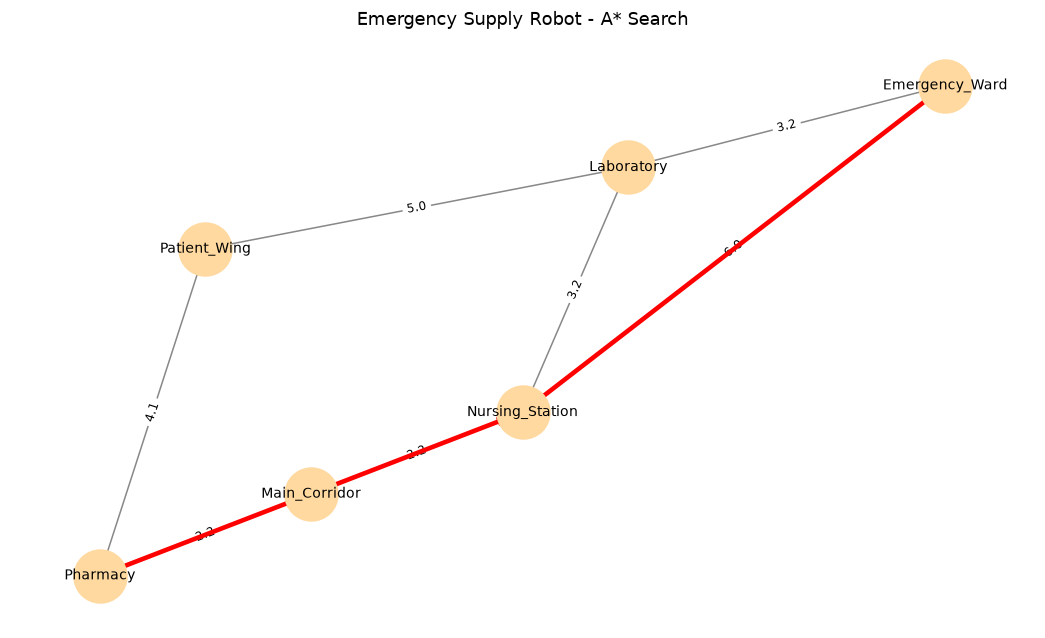

In [9]:
# 7. NetworkX visualization
G = nx.DiGraph()

for node, neighbors in hospital_graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(G, pos, node_color="#ffd9a0", node_size=1200)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edges(G, pos, arrows=True, edge_color="#888888")
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "weight"), font_size=8)

path_edges = list(zip(path, path[1:]))
nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3)

plt.title("Emergency Supply Robot - A* Search")
plt.axis("off")
plt.show()

GBFS would primarily ask:

"Which node appears closest to the Emergency Ward?"

A* instead asks:

"Considering both the cost already travelled and the estimated remaining cost, which node has the lowest estimated total cost?"

### Task 4: Weighted A* for Autonomous Delivery Drone

In [10]:
import math
import heapq
import pandas as pd

# 1. Location Coordinates

locations = {
    "Distribution_Center": (0, 0),
    "Zone_A": (2, 1),
    "Zone_B": (1, 4),
    "Zone_C": (4, 2),
    "Zone_D": (5, 5),
    "Customer_Building": (8, 6)
}

# 2. Weighted Graph

graph = {
    "Distribution_Center": {
        "Zone_A": 2.2,
        "Zone_B": 3.0
    },

    "Zone_A": {
        "Zone_C": 2.2
    },

    "Zone_B": {
        "Zone_D": 5.0
    },

    "Zone_C": {
        "Zone_D": 3.2,
        "Customer_Building": 6.0
    },

    "Zone_D": {
        "Customer_Building": 3.2
    },

    "Customer_Building": {}
}

# 3. Euclidean Heuristic

def heuristic(node, goal):
    x1, y1 = locations[node]
    x2, y2 = locations[goal]
    return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

# 4. Display Heuristic Values
goal = "Customer_Building"

heuristic_data = []

for node in locations:

    heuristic_data.append({
        "Node": node,
        "h(n)": round(heuristic(node, goal), 2)
    })

heuristic_df = pd.DataFrame(heuristic_data)

print("Heuristic Values:")
print(heuristic_df.to_string(index=False))

# 5. Weighted A* Search
# f(n) = g(n) + w * h(n)


def weighted_a_star(start, goal, graph, weight):
    frontier = [(weight * heuristic(start, goal), start)]
    g_cost = {start: 0.0}
    came_from = {start: None}
    expanded = []
    visited = set()

    while frontier:
        _, current = heapq.heappop(frontier)

        if current in visited:
            continue

        visited.add(current)
        expanded.append(current)

        if current == goal:
            break

        for neighbor, cost in graph[current].items():
            new_g = g_cost[current] + cost
            if neighbor not in g_cost or new_g < g_cost[neighbor]:
                g_cost[neighbor] = new_g
                came_from[neighbor] = current
                f = new_g + weight * heuristic(neighbor, goal)
                heapq.heappush(frontier, (f, neighbor))

    if goal not in g_cost:
        return None, 0.0, expanded

    path = []
    node = goal
    while node is not None:
        path.append(node)
        node = came_from[node]
    path.reverse()

    return path, g_cost[goal], expanded

# 6. Run Weighted A* for All Required Weights
start = "Distribution_Center"
goal = "Customer_Building"

weights = [1, 1.5, 2, 3]

results = []

for w in weights:

    path, cost, expansion_order = weighted_a_star(
        start,
        goal,
        graph,
        w
    )

    results.append({
        "Weight": w,
        "Solution Path": " → ".join(path),
        "Total Cost": round(cost, 2),
        "Nodes Expanded": len(expansion_order),
        "Expansion Order": " → ".join(expansion_order)
    })


# 7. Display Results in dataframe
results_df = pd.DataFrame(results)

print("\nWeighted A* Results")
print("-------------------")
print(
    results_df[
        ["Weight", "Solution Path", "Total Cost", "Nodes Expanded"]
    ].to_string(index=False)
)


# 8. Display Detailed Expansion Orders
print("\nExpansion Orders")
print("----------------")

for r in results:
    print(f"w = {r['Weight']}:  {r['Expansion Order']}")


# ***
# Expected Main Results
# ***

# w = 1:
# Distribution_Center → Zone_A → Zone_C → Customer_Building
# Cost = 10.4
#
# w = 1.5:
# Distribution_Center → Zone_A → Zone_C → Customer_Building
# Cost = 10.4
#
# w = 2:
# Distribution_Center → Zone_B → Zone_D → Customer_Building
# Cost = 11.2
#
# w = 3:
# Distribution_Center → Zone_B → Zone_D → Customer_Building
# Cost = 11.2

Heuristic Values:
               Node  h(n)
Distribution_Center 10.00
             Zone_A  7.81
             Zone_B  7.28
             Zone_C  5.66
             Zone_D  3.16
  Customer_Building  0.00

Weighted A* Results
-------------------
 Weight                                             Solution Path  Total Cost  Nodes Expanded
    1.0 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               5
    1.5 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               4
    2.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4
    3.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4

Expansion Orders
----------------
w = 1:  Distribution_Center → Zone_A → Zone_C → Zone_B → Customer_Building
w = 1.5:  Distribution_Center → Zone_A → Zone_C → Customer_Building
w = 2:  Distribution_Center → Zone_B → Zone_D → Customer_Building
w = 3:  Distribution_Center → Zone_B → Zone_D

#### NetworkX visualization

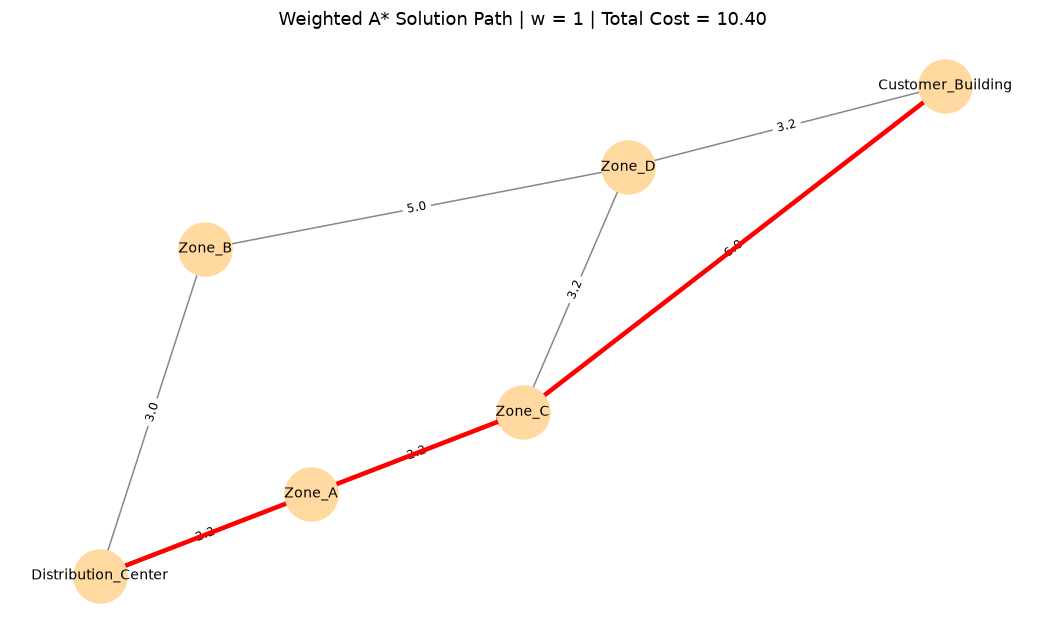

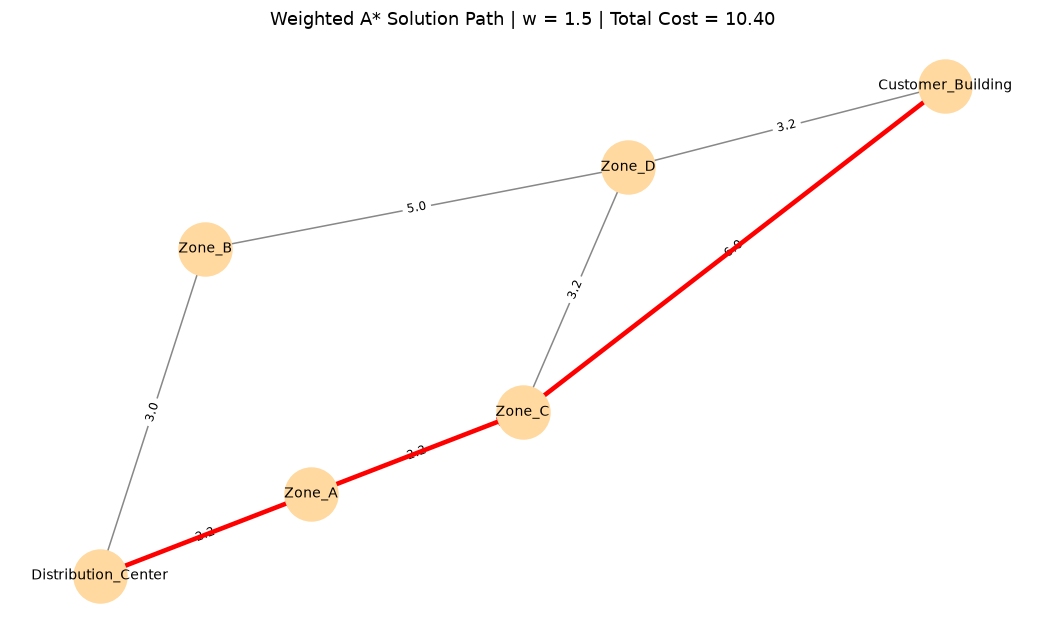

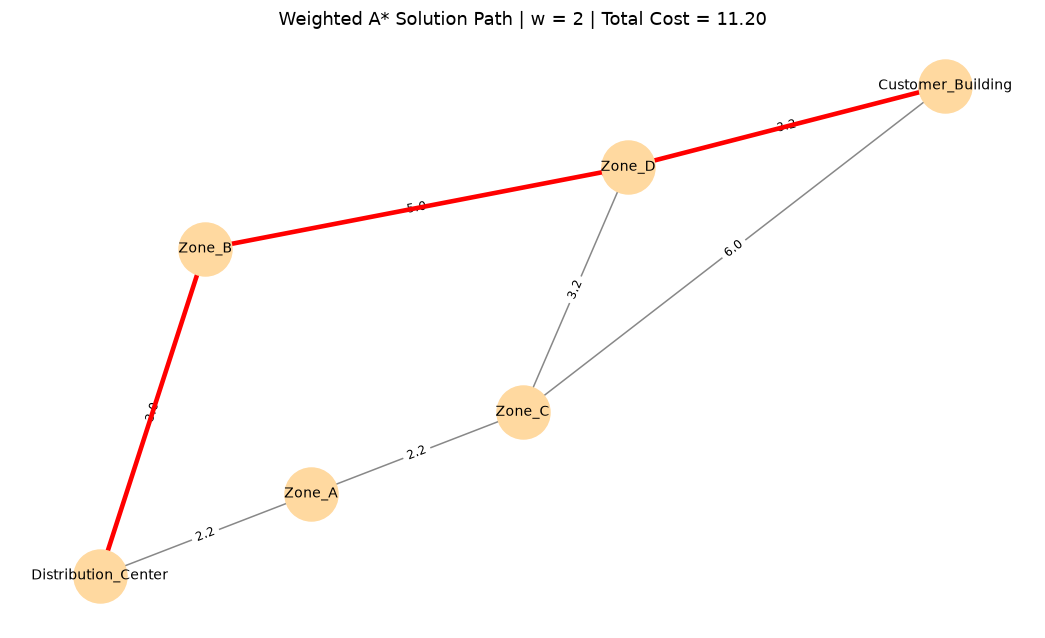

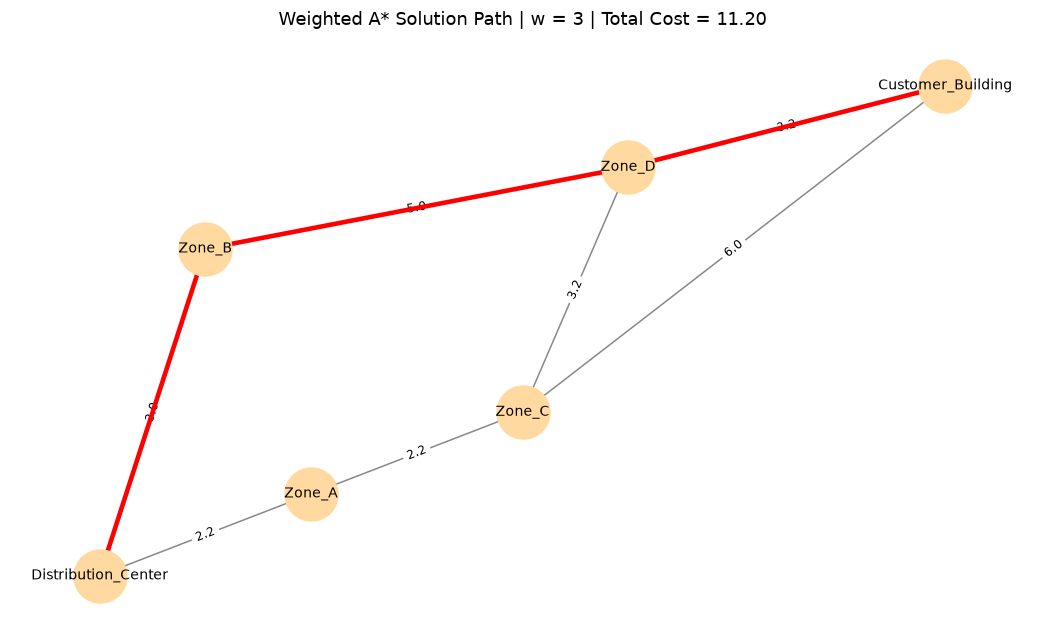

In [11]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Create NetworkX Graph

G = nx.DiGraph()

# Add nodes with their coordinates
for node, position in locations.items():

    G.add_node(
        node,
        pos=position
    )


# Add weighted edges
for node, neighbors in graph.items():

    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

# 2. Node Positions
pos = locations

# 3. Visualize Weighted A* Result for Each Weight

for w in weights:

    # Run Weighted A*
    path, cost, expansion_order = weighted_a_star(start, goal, graph, w)

    plt.figure(figsize=(12, 7))

    nx.draw_networkx_nodes(G, pos, node_color="#ffd9a0", node_size=1200)
    nx.draw_networkx_labels(G, pos, font_size=9)
    nx.draw_networkx_edges(G, pos, arrows=True, edge_color="#888888")
    nx.draw_networkx_edge_labels(
        G, pos, nx.get_edge_attributes(G, "weight"), font_size=8
    )

    path_edges = list(zip(path, path[1:]))
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3)

    plt.title(
        f"Weighted A* Solution Path | w = {w} | "
        f"Total Cost = {cost:.2f}"
    )

    plt.axis("off")

    plt.show()

#### Expansion order

This means:

In what order did the search algorithm remove/select nodes from the frontier and process them?

For example:

Expanded:
S → A → B → C → D → G

The algorithm may explore some nodes that are ultimately not part of the final route.

#### Solution path

This means:

Which nodes form the final route from start to goal?

For example:

Solution:
S → A → C → G

Here:

Expansion order:  S → A → B → C → D → G
Solution path:    S → A → C → G